<a href="https://colab.research.google.com/github/Hunny2007/Breast-Cancer-Prediction/blob/main/Breast_Cancer_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Importing imp Libraries**

In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
!pip install mpld3
import mpld3 as mpl


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier,export_graphviz
from sklearn import metrics






   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.1/203.1 kB 1.1 MB/s eta 0:00:00


In [4]:
df=pd.read_csv("/content/data.csv",header=0)
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [6]:
df.drop(columns=['id','unnamed: 32'], errors= 'ignore',inplace=True)
print(df.shape)

(569, 32)


In [7]:
df.diagnosis.unique()

array(['M', 'B'], dtype=object)

In [8]:
df["diagnosis"]=df['diagnosis'].map({'M': 1,'B':0})

In [9]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


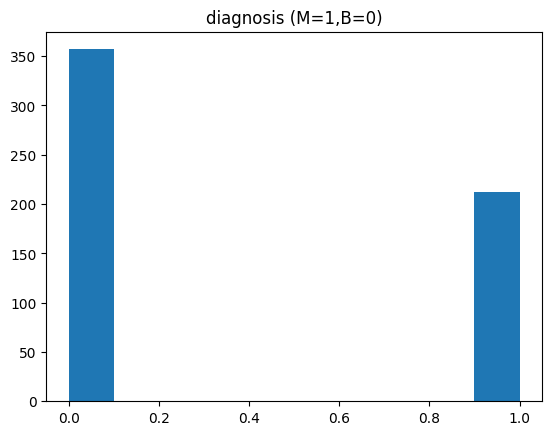

In [10]:
plt.hist(df['diagnosis'])
plt.title('diagnosis (M=1,B=0)')
plt.show()

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    int64  
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [12]:
features_mean=list(df.columns[1:11]) #split into two based on diagnosis
dfM=df[df['diagnosis']==1]
dfB=df[df['diagnosis']==0]

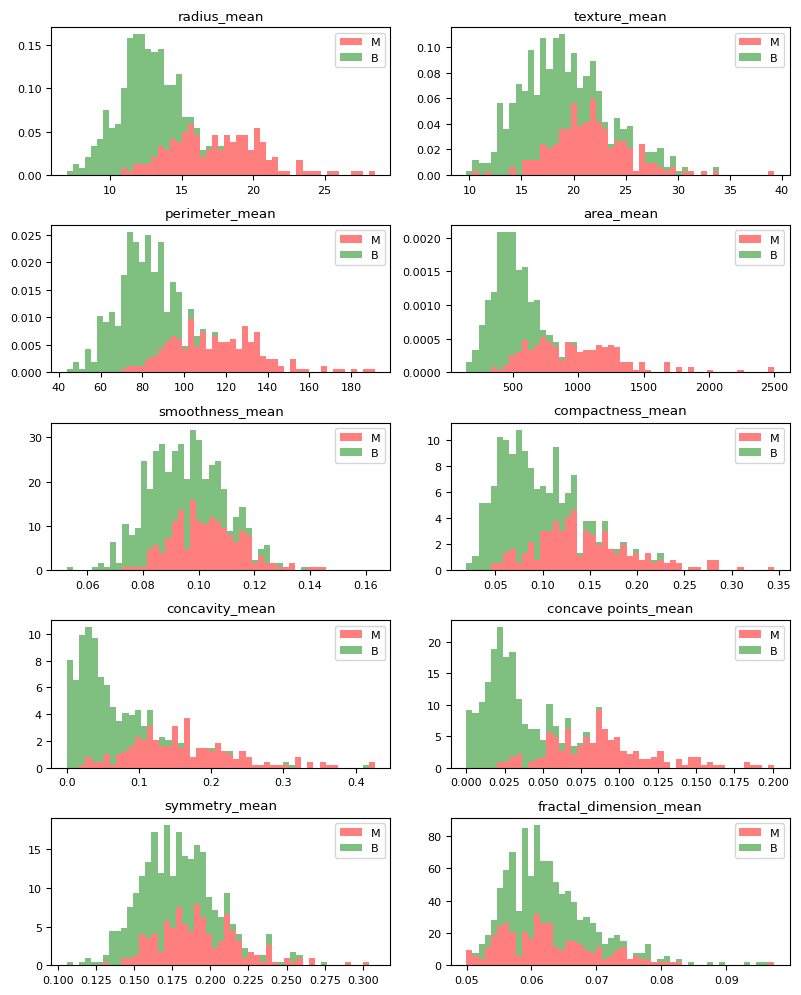

In [15]:
#stack the data
plt.rcParams.update({'font.size':8})
fig,axes=plt.subplots(nrows=5,ncols=2,figsize=(8,10))
axes=axes.ravel()
for idx,ax in enumerate(axes):
  binwidth= (max(df[features_mean[idx]]) - min(df[features_mean[idx]]))/50
  ax.hist([dfM[features_mean[idx]],dfB[features_mean[idx]]],bins=np.arange(min(df[features_mean[idx]]), max(df[features_mean[idx]]) + binwidth,binwidth), alpha=0.5,stacked=True,density =True, label=['M','B'], color=['r','g'])
  ax.legend(loc='upper right')
  ax.set_title(features_mean[idx])
plt.tight_layout()
plt.show()

**spilt the dataset**

In [16]:
traindf,testdf=train_test_split(df,test_size=0.30)

In [26]:
def classification_model(model,data,predictors,outcome):
  model.fit(data[predictors],data[outcome])

  predictions=model.predict(data[predictors])

  accuracy=metrics.accuracy_score(predictions,data[outcome])

  print("Accuracy: %s  "%"{0: 3%}".format(accuracy))

  kf=KFold(n_splits=5)
  error=[]
  for train,test in kf.split(data):
    train_predictors=data[predictors].iloc[train,:]
    train_target=data[outcome].iloc[train]
    model.fit(train_predictors,train_target)
    error.append(model.score(data[predictors].iloc[test,:],data[outcome].iloc[test]))
  print("Cross Validations Score : %s"%"{0: 3%}".format(np.mean(error)))
  model.fit(data[predictors],data[outcome])


**Logistic Regression Model**

In [27]:
predictor_var=['radius_mean','perimeter_mean','area_mean','compactness_mean','concave points_mean']
outcome_var='diagnosis'
model=LogisticRegression(max_iter=1000)
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy:  91.457286%  
Cross Validations Score :  90.968354%


**Decision Tree Model**

In [28]:
predictor_var=['radius_mean','perimeter_mean','area_mean','compactness_mean','concave points_mean']
outcome_var='diagnosis'
model= DecisionTreeClassifier()
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy:  100.000000%  
Cross Validations Score :  90.974684%


In [29]:
predictor_var=['radius_mean']
outcome_var='diagnosis'
model=LogisticRegression(max_iter=1000)
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy:  90.452261%  
Cross Validations Score :  90.455696%


**RandomForest**

In [ ]:
predictor_var=['radius_mean','perimeter_mean','area_mean','compactness_mean','concave points_mean']
outcome_var='diagnosis'
model=RandomForestClassifier(n_estimators=100,min_samples_split=25,max_depth=7,max_features=2)
classification_model(model,traindf,predictor_var,outcome_var)

In [37]:
predictor_var = features_mean
outcome_var='diagnosis'
model=RandomForestClassifier(n_estimators=100,min_samples_split=25,max_depth=7,max_features=2)
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy:  96.984925%  
Cross Validations Score :  94.731013%


In [35]:
predictor_var=['radius_mean']
outcome_var='diagnosis'
model=RandomForestClassifier(n_estimators=100,min_samples_split=25,max_depth=7,max_features=2)
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy:  91.206030%  
Cross Validations Score :  88.946203%


In [38]:
featimp=pd.Series(model.feature_importances_,index=predictor_var).sort_values(ascending=False)
print(featimp)

concave points_mean       0.199818
perimeter_mean            0.186830
area_mean                 0.166452
concavity_mean            0.165529
radius_mean               0.123114
compactness_mean          0.089646
texture_mean              0.034740
smoothness_mean           0.017345
symmetry_mean             0.009051
fractal_dimension_mean    0.007475
dtype: float64


In [41]:
predictor_var=['radius_mean','concave points_mean','concavity_mean','perimeter_mean','area_mean']
outcome_var='diagnosis'
model=RandomForestClassifier(n_estimators=100,min_samples_split=25,max_depth=7,max_features=2)
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy:  96.231156%  
Cross Validations Score :  94.227848%


**using on test dataset**

In [42]:
predictor_var = features_mean
outcome_var='diagnosis'
model=RandomForestClassifier(n_estimators=100,min_samples_split=25,max_depth=7,max_features=2)
classification_model(model,traindf,predictor_var,outcome_var)

Accuracy:  97.236181%  
Cross Validations Score :  93.974684%
